# 7.2.1 - Model: Random Forest Lite (stemmed variant)

**Finding and training the "lite" version of the Random Forest classifier - with a significantly smaller .joblib file and minimal loss in F1 score compared to the heavy version from `7.1.1`.**

## Motivation

In `7.1.1`, GridSearchCV selected `max_depth=500, min_samples_leaf=1, n_estimators=2500` for the stemmed variant, which resulted in a **6.4GB** model (F1 = 0.8838).

For the purposes of this work, a file of this size is impractical to store and share, while almost all other models in this work are below 2MB.

The goal of this file is not to find the best possible F1 (that has already been done in `7.1.1`), but to find a reasonable compromise between file size and F1 score, i.e. a "lite" version that:
- targets a file size that does not deviate too much from the other `.joblib` files and is not (much) larger than 10MB
- keeps the F1 as close as possible to the heavy version
- is saved separately from the original model, for comparison in `10_evaluation.ipynb`

## Why GridSearchCV from `train_and_evaluate()` is not sufficient here

`train_and_evaluate()` (from `src/modeling.py`) selects hyperparameters exclusively based on F1 score - it has no knowledge of the size of the resulting file.

To find a combination that balances F1 and size, we first have to manually explore the hyperparameter space and measure both for each combination.

Only after selecting the final combination do we call `train_and_evaluate()` with that single (fixed) combination in order to obtain the official, saved model, metrics and confusion matrix - in the same way as with all other models in the work.

## Hyperparameters

- `n_estimators` - number of trees in the forest
  - More trees → more stable, reliable results (averaging across more "votes")
  - But also slower training - each additional tree increases training time

- `max_depth` - maximum depth of each individual tree in the forest

- `max_features` - how many features are randomly considered at each split
  - `"sqrt"` - considers √66.682 ≈ 258 features per split
  - `"log2"` - considers log₂(66.682) ≈ 17 features per split
  - Fewer features per split means more diverse trees (a lower chance that two trees make the same split), which can improve the ensemble effect

- `min_samples_leaf` - minimum number of samples that a leaf must contain for a split to be allowed
  - A higher value prevents the creation of very small leaves and thus further regularizes the model

## Which hyperparameters do we examine, and which do we fix

From `7.1.x` we know that `max_features='log2'` was the best (and intuitively makes sense - fewer features per split means more diverse trees), so we fix it.

We focus on three hyperparameters that directly determine file size:

- `max_depth`:
    - The biggest "driver" of size
    - With 39.665 training examples, a fully balanced tree would theoretically need a depth of only ~15 to separate all examples
    - We expect F1 to grow quickly up to some moderate depth and then slow down, while file size grows almost linearly (deeper trees = more nodes)

- `min_samples_leaf`:
    - In `7.1.1`, 1 was selected (the smallest possible value), which allows very small leaves and contributes to the enormous size
    - We expect larger values to minimally reduce F1 while significantly reducing size

- `n_estimators`:
    - We expect size to grow approximately linearly with the number of trees, while the F1 gain from additional trees quickly decreases after several hundred/thousand trees.

<br>

<br>

## Theoretical background

Random Forest is an ensemble method - instead of training a single tree (as in `6.1`), it trains many independent Decision Tree models and combines their predictions into one final decision in order to obtain a more stable and accurate classifier.

Each tree in the forest is built in a slightly different way than a standard Decision Tree:
- Bootstrap sampling (bagging) - each tree is trained on its own random sample of the TRAIN set, drawn with replacement (the same example may appear multiple times, while some examples may be completely omitted)
- Random subset of features per split - at each node split, the tree does not consider all features (as a standard Decision Tree does), but only a randomly selected subset (controlled by the `max_features` parameter)
- Multiple trees – the number of trees in the forest is determined by the `n_estimators` parameter (a larger number of trees generally produces more stable results, but increases training time).

The final prediction of the entire forest is the majority vote of all individual trees.

Why this helps:
- An individual tree is unstable - a small change in the training data can produce a completely different tree, and it is prone to overfitting
- By averaging across many different, weakly dependent trees, the errors of individual trees cancel each other out, and the forest as a whole generalizes better to new data

Cost:
- We lose the direct interpretability of an individual tree (now we have many trees instead of one, so we cannot simply "follow" a single sequence of decisions)
- We retain some degree of interpretability through `feature_importances_` (averaged across all trees in the forest, instead of coming from a single tree as in `6.1`)

## Note about the name `max_features`

`max_features` here is not the same parameter as `max_features` from `3_vectorization.ipynb` (there it controlled the size of the entire TF-IDF vocabulary).

`max_features` here controls how many features are randomly considered at each individual node split within a single tree.

## Processing flow:

1. We load the previously prepared stemmed TF-IDF data using the `load_variant()` function

2. Coarse search - we examine a wide range of hyperparameters to get a rough picture of the relationship between F1 and file size

3. Fine search - we examine in more detail the range of hyperparameters that produced the best results in the coarse search

4. Display and select the final hyperparameter combination for which we obtained the best relationship between F1 and file size

5. We call the shared `train_and_evaluate()` function for the predetermined hyperparameters

6. We analyze `feature_importances_` (averaged across all trees in the forest) to see which terms contribute the most to the decisions


In [ ]:
import sys
sys.path.append("..")

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

TMP_MODEL_PATH = Path("../models/_tmp_lite_search.joblib")

## Data Loading

We load the stemmed variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("stemmed")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 66682)
Test:  (9917, 66682)


## Helper Function for Measuring F1 and File Size

For each hyperparameter combination:

1. We estimate F1 using 5-fold cross-validation on the TRAIN set (`cross_val_score`) (the same number of folds as in `train_and_evaluate()`, for comparability and reliability of the F1 values without touching the TEST set)

2. We train the model on the entire TRAIN set (the same thing that happens in the final step) and temporarily save it to disk in order to measure the actual `.joblib` file size (the size depends on the structure of the trained trees and cannot be reliably estimated without actually saving the model)

3. We delete the temporary file after measurement (we do not clutter the `models/` folder with intermediate results)

The TEST set is not used at all during this research phase - it is reserved for the final evaluation of the selected model, following the same principle used by `train_and_evaluate()`.

`evaluate_combo` - for a given hyperparameter combination, returns the estimated CV F1 and the size (in MB) of the resulting `.joblib` file trained on the entire TRAIN set.


In [ ]:
def evaluate_combo(max_depth, min_samples_leaf, n_estimators, max_features="log2"):
    model = RandomForestClassifier(
        max_depth=max_depth,
        max_features=max_features,
        min_samples_leaf=min_samples_leaf,
        n_estimators=n_estimators,
        random_state=1,
        n_jobs=-1,
    )

    start = time.time()

    # F1 procena (bez čuvanja modela) kao srednja vrednost od 5-fold cross-validation
    cv_f1 = cross_val_score(model, X_train, y_train, cv=5, scoring="f1", n_jobs=-1).mean()

    # Trening na celom TRAIN skupu, radi merenja stvarne veličine fajla
    model.fit(X_train, y_train)
    joblib.dump(model, TMP_MODEL_PATH)
    size_mb = TMP_MODEL_PATH.stat().st_size / (1024 ** 2)
    TMP_MODEL_PATH.unlink()                                 # brišemo privremeni fajl

    elapsed = time.time() - start

    return {
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "n_estimators": n_estimators,
        "f1": cv_f1,
        "size_mb": size_mb,
        "time_s": elapsed,
    }

## Step 1: Coarse Search

We examine a wide range of `max_depth` values (including the one from `7.1.1`, `max_depth=500`, for comparison), combined with `min_samples_leaf` and `n_estimators`, in order to get a rough picture of the relationship between F1 and file size before focusing on a narrower region.


In [4]:
coarse_max_depth = [10, 50, 200, 500]
coarse_min_samples_leaf = [2, 3]
coarse_n_estimators = [1000, 1500, 2000]

coarse_results = []
for depth in coarse_max_depth:
    for leaf in coarse_min_samples_leaf:
        for n_est in coarse_n_estimators:
            result = evaluate_combo(depth, leaf, n_est)
            coarse_results.append(result)

coarse_df = pd.DataFrame(coarse_results)

coarse_df.style.format({"f1": "{:.4f}", "size_mb": "{:.1f}", "time_s": "{:.0f}"})

,max_depth,min_samples_leaf,n_estimators,f1,size_mb,time_s
0,10,2,1000,0.8482,3.5,26
1,10,2,1500,0.8518,5.2,39
2,10,2,2000,0.8521,6.9,40
3,10,3,1000,0.8483,2.9,21
4,10,3,1500,0.8518,4.3,30
5,10,3,2000,0.8525,5.8,41
6,50,2,1000,0.8712,26.7,37
7,50,2,1500,0.8728,39.7,54
8,50,2,2000,0.8729,52.9,73
9,50,3,1000,0.8713,17.8,34


## Comment on the Coarse Search

The results confirm the expected trade-off between F1 score and model size and support the assumptions from the introduction:

- `max_depth`
    - **Dominant factor determining model size, with clearly diminishing returns on F1**
    - The results confirm the main hypotheses from the introduction and clearly show the trade-off between F1 score and model size
    - Average F1 increases from: 0.8508 (10) -> 0.8722 (50) -> 0.8787 (200) -> 0.8801 (500)
    - Average size increases from: 4.77 MB (10) -> 33.94 MB (50) -> 118.06 MB (200) -> 157.28 MB (500)
    - From 10 to 50, F1 increases by ~0.021 for a ~7x larger file -> a relatively good trade-off if model size is not strictly limited
    - From 50 to 500, F1 increases by only ~0.008 for a file that is ~5x larger -> a significantly smaller gain in F1 relative to the additional model size

- `min_samples_leaf`
    - **2 vs. 3 has a negligible impact on F1, but a noticeable impact on size**
    - For `min_samples_leaf=2`, the average F1 is around 0.8735, while the average size is around 70.4 MB
    - For `min_samples_leaf=3`, the average F1 is around 0.8733, while the average size drops to around 52.4 MB
    - Moving from `leaf=2` to `leaf=3` costs only around 0.0002 F1, while reducing the model size by around 26%
    - The effect is particularly pronounced at greater depths (for `max_depth=500` and `n_estimators=1000`, a loss of 0.0013 F1 results in a reduction in model size of around 45%)
    - This represents a useful way to regularize and reduce the model size
    - The fine search should also test values greater than 3

- `n_estimators`
    - **Model size and training time grow approximately linearly, while the gain in F1 quickly diminishes**
    - In most tested combinations, moving from 1000 to 1500 trees provides a small improvement in F1
    - Moving from 1500 to 2000 generally provides an even smaller gain or even a slight decrease in F1
    - Therefore, after approximately 1000-1500 trees, additional trees generally provide very little gain, while still significantly increasing file size and training time

Based on the coarse search:
- `max_depth` proves to be the most important parameter for finding the lite model, because it directly controls how complex individual trees can be and therefore how many nodes, and consequently how much data, the model needs to store.
- `min_samples_leaf` proves to be a useful additional mechanism for reducing size with a relatively small loss in F1
- `n_estimators` should be kept at moderately high values because after a certain number of trees, the gain in F1 quickly diminishes.

None of the combinations from the coarse search come close to our target size (~10MB) while maintaining a satisfactory F1.

There is a large gap between `max_depth=10` and `max_depth=50` (5.18MB -> 26.68MB) where a better trade-off is likely to exist.

We examine this region with a finer search.


## Step 2: Fine Search Around Target Values

We zoom in on `max_depth` between 10 and 50 (values 15, 20, 25, 30, 35, 40)

We expand `min_samples_leaf` with values above 3

We limit `n_estimators` to between 1000 and 1500 - in the coarse step, going above this range rarely paid off at smaller depths.


In [ ]:
fine_max_depth = [15, 20, 25, 30, 35, 40]
fine_min_samples_leaf = [2, 3, 4, 5]
fine_n_estimators = [1000, 1250, 1500]

fine_results = []
for depth in fine_max_depth:
    for leaf in fine_min_samples_leaf:
        for n_est in fine_n_estimators:
            result = evaluate_combo(depth, leaf, n_est)
            fine_results.append(result)

fine_df = pd.DataFrame(fine_results)
all_results_df = pd.concat([coarse_df, fine_df], ignore_index=True)

## Pareto Analysis: Selecting the Final Combination

From all tested combinations (coarse + fine), we select those that are Pareto-optimal around the target size.

In other words, there is no other combination that is simultaneously smaller and better than them.


In [7]:
sorted_df = all_results_df.sort_values("size_mb").reset_index(drop=True)

pareto_rows = []
best_f1_so_far = -np.inf

for _, row in sorted_df.iterrows():
    if row["f1"] > best_f1_so_far:
        pareto_rows.append(row)
        best_f1_so_far = row["f1"]

pareto_df = pd.DataFrame(pareto_rows).reset_index(drop=True)
pareto_df[["max_depth", "min_samples_leaf", "n_estimators", "f1", "size_mb"]].style.format({"max_depth": "{:.0f}", "min_samples_leaf": "{:.0f}", "n_estimators": "{:.0f}", "f1": "{:.4f}", "size_mb": "{:.1f}"})

,max_depth,min_samples_leaf,n_estimators,f1,size_mb
0,10,3,1000,0.8483,2.9
1,15,5,1000,0.8590,3.7
2,15,3,1000,0.8595,4.5
3,15,5,1250,0.8612,4.6
4,20,5,1000,0.8629,5.0
5,20,5,1250,0.8647,6.2
6,25,5,1000,0.8654,6.2
7,30,5,1000,0.8664,7.4
8,25,5,1250,0.8671,7.7
9,30,4,1000,0.8672,8.3


## Visual Reprezentation


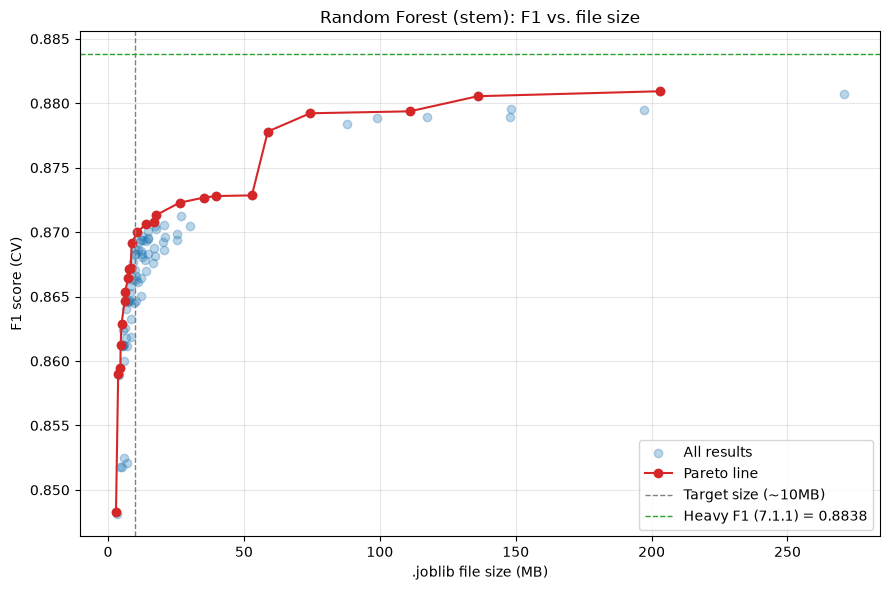

In [8]:
plt.figure(figsize=(9, 6))
plt.scatter(all_results_df["size_mb"], all_results_df["f1"], alpha=0.3, label="All results")
plt.plot(pareto_df["size_mb"], pareto_df["f1"], marker="o", color="tab:red", label="Pareto line")

plt.axvline(10, color="gray", linestyle="--", linewidth=1, label="Target size (~10MB)")
plt.axhline(0.8838, color="tab:green", linestyle="--", linewidth=1, label="Heavy F1 (7.1.1) = 0.8838")

plt.xlabel(".joblib file size (MB)")
plt.ylabel("F1 score (CV)")
plt.title("Random Forest (stem): F1 vs. file size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final Combination Selection

We select `max_depth=35, min_samples_leaf=5, n_estimators=1000, max_features='log2'`:

- The size (8.7MB) is close to the target value of ~10MB, with a small amount of room below the limit

- It lies on the Pareto front and represents a better F1/size trade-off than its neighboring points on the front:
    - The next point (`max_depth=35, min_samples_leaf=5, n_estimators=1250`) provides only +0.0008 F1 for a 20% larger file (10.8MB)
    - The point after that (`max_depth=40, min_samples_leaf=4, n_estimators=1250`) provides only an additional +0.0007 F1 for another 30% larger file (14.0MB)

- The F1 vs. file size graph shows that a truly, significantly better point exists only at ~59MB (`max_depth=200, min_samples_leaf=3, n_estimators=1000`, F1 0.8778) - but that would exceed the target size by 6x, so we stick with the smaller, targeted model

- The selection is identical to the one from `7.2.0` (base variant) - this confirms the assumption that file size, and therefore the best trade-off point, depends primarily on the structure of the trees, rather than the preprocessing variant

- Compared to the heavy version (F1-0.8838, size-6.4GB), we lose ~0.015 F1 (around 1.7%) for a file that is over 700x smaller

Note:
- The F1 above is an estimate obtained through cross-validation on the TRAIN set
- The final evaluation on the TEST set, which we have not used so far, is obtained only now, through `train_and_evaluate()` from `src/modeling.py`


========== lite_random_forest (stem) ==========
Best parameters: {'max_depth': 35, 'max_features': 'log2', 'min_samples_leaf': 5, 'n_estimators': 1000}
GridSearchCV time: 44.8s

Accuracy  : 0.8605
Precision : 0.8241
Recall    : 0.9180
F1        : 0.8685


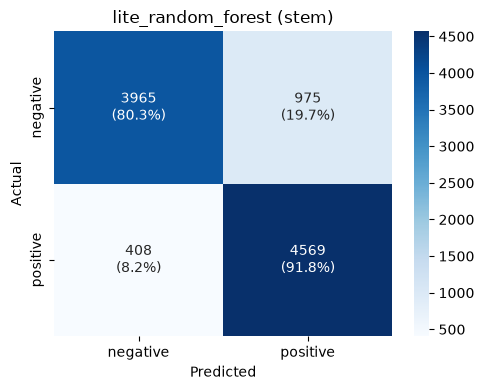


Saved:
  ..\models\lite_random_forest_stem.joblib
  ..\results\metrics\lite_random_forest_stem.json
  ..\results\figures\lite_random_forest_stem_confusion_matrix.png


In [10]:
model = RandomForestClassifier(random_state=1)

param_grid = {
    "n_estimators": [1000],
    "max_depth": [35],
    "max_features": ["log2"],
    "min_samples_leaf": [5],
}

metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="lite_random_forest",
    variant="stem",
)

## Feature Importance - Comparison with the Heavy Version

`feature_importances_` represents a measure of feature importance.

The value shows how much a particular term contributed to reducing "impurity" across all splits.

A higher value means that the feature made a greater contribution to reducing impurity during splits in the trees of the Random Forest model.

The same principle as in `7.1.1` - `feature_importances_` is averaged across all trees.

We expect the lite version, with significantly fewer trees (1000 vs 2500) and shallower trees (`max_depth=35` vs 500), to use a smaller portion of the vocabulary than the heavy version (which used 100% of the terms) - there is less opportunity for "rare", specific terms to receive non-zero importance.


In [11]:
best_model = joblib.load("../models/lite_random_forest_stem.joblib")
vectorizer = joblib.load("../models/tfidf_vectorizer_stem.joblib")

feature_names = np.array(vectorizer.get_feature_names_out())
importances = best_model.feature_importances_

top_idx = np.argsort(importances)[-20:][::-1]

print("Top 20 most influential terms (lite):")
for idx in top_idx:
    print(f"  {feature_names[idx]:30s}  {importances[idx]:.4f}")

n_zero_importance = np.sum(importances == 0)
print(f"\nNumber of terms that the forest never used for splitting: {n_zero_importance} out of {len(importances)} ({n_zero_importance / len(importances):.1%})")

Top 20 most influential terms (lite):
  love                            0.0053
  worst                           0.0047
  not even                        0.0045
  aw                              0.0040
  no                              0.0038
  poor                            0.0037
  horribl                         0.0036
  wast                            0.0035
  noth                            0.0034
  suppos                          0.0034
  beauti                          0.0033
  wors                            0.0032
  great                           0.0031
  script                          0.0031
  excel                           0.0029
  favorit                         0.0029
  bad                             0.0029
  amaz                            0.0027
  bore                            0.0027
  best                            0.0026

Number of terms that the forest never used for splitting: 48826 out of 66682 (73.2%)


## Conclusions

- Instead of the standard `GridSearchCV` (which selects hyperparameters exclusively based on F1 score), the light version was searched for using a targeted approach that measured both F1 and the actual size of the `.joblib` file for each combination - coarse followed by fine search, then Pareto analysis

- The F1 vs. file size graph revealed that the curve is not smooth: after ~14MB, a long plateau appears (up to ~53MB) where additional size contributes almost nothing to F1, and only at ~59MB does a significant jump occur (F1 0.8778).
Since the goal was to stay close to ~10MB, this jump was not used, but it is worth mentioning as a finding that would be interesting if size were not the priority

- Selected final combination: `max_depth=35, min_samples_leaf=5, n_estimators=1000, max_features='log2'` - the best F1 available without leaving the targeted size range (the two neighboring, "more expensive" points on the Pareto front offered a negligible improvement in F1 for a disproportionately larger file)

- Final results on the TEST set (`lite_random_forest`, stem):
  - Accuracy  : 0.8605
  - Precision : 0.8241
  - Recall    : 0.9180
  - F1        : 0.8685
  - Saved file size: 8.91 MB

- Test F1 (0.8685) is very close to the CV estimate from the search (0.8692, difference 0.0007)

- Compared to the heavy version (`7.1.1`: F1-0.8838, size-6.4GB), the light version loses 0.0153 F1 (~1.7%), with a file that is ~700x smaller

- Recall (0.9180) is significantly higher than precision (0.8241) - meaning that the model successfully identifies most positive reviews.
The same asymmetry exists in the heavy version

- Feature importance: the light version used only 26.8% of the vocabulary for splits (48.826 out of 66.682 terms were never used), compared to 100% for the heavy version - a direct consequence of the smaller depth (35 vs 500) and fewer trees (1000 vs 2500)

- The core set of the most influential terms is almost identical to the heavy version (worst, aw, no, poor, wast, noth, great, excel, bad, bore, best, "not even" - appearing in the top 20 in both models), confirming that the light model, although much smaller, relies on the same robust sentiment signals

- New, semantically meaningful terms also appear (horribl, beauti, wors, amaz, favorit, script)

<br>

Overall conclusion: the cost of ~1.7% F1 for a ~700x smaller file represents an extremely favorable trade-off - the light version is practically usable while retaining most of the predictive power of the heavy model.
